# S&P 500 Movement Prediction

**Question:** can historical price and volume data predict whether the S&P 500 will close higher tomorrow?

**Approach:** a `RandomForestClassifier`, validated with a **walk-forward backtest** (train on the past, test on the following year, repeat) rather than a random split, which would leak future information into a time-series problem. Every result is compared against the market's base rate and against buy-and-hold, because a model score only means something relative to those.

**Data:** daily S&P 500 (`^GSPC`) prices from `yfinance`, downloaded on 18 Oct 2026 and saved as `sp500_snapshot.csv` (the data runs through 16 Oct 2026). The notebook loads this file, so anyone who runs it gets the same results.

**Requirements:** `pandas`, `scikit-learn`, `matplotlib`, `plotly` (plus `yfinance`, only if the CSV is missing).

## What is the S&P 500?

The **S&P 500** (Standard & Poor's 500) is a stock market index that tracks roughly 500 of the largest publicly traded companies in the United States, across nearly every major industry. Rather than following a single company, it acts as a broad snapshot of how the U.S. stock market is performing.

It is widely used as a market health indicator, as a benchmark that fund managers compare themselves against, and as the basis for many index funds and ETFs. It was chosen here because it reflects overall market movement rather than one company, which makes it a reasonable target for testing whether price history alone can predict short-term direction.

## Loading the Data

In [1]:
import os
import pandas as pd

SNAPSHOT = "sp500_snapshot.csv"

# Download once, then always load the saved file so results are reproducible
if not os.path.exists(SNAPSHOT):
    import yfinance as yf   # pip install yfinance (only needed for the first download)
    yf.Ticker("^GSPC").history(period="max").to_csv(SNAPSHOT)

sp500 = pd.read_csv(SNAPSHOT, index_col=0)

# yfinance stores timezone offsets (-05:00 / -04:00); convert to plain dates so date slicing works
sp500.index = pd.to_datetime(sp500.index, utc=True).tz_localize(None).normalize()

sp500.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-12,7813.040039,7821.669922,7796.939941,7807.240234,4148500000,0.0,0.0
2026-10-13,7795.270020,7814.149902,7786.109863,7805.450195,4869340000,0.0,0.0
2026-10-14,7774.180176,7789.149902,7693.310059,7718.939941,5955580000,0.0,0.0
2026-10-15,7687.310059,7754.149902,7669.660156,7744.060059,6055670000,0.0,0.0
2026-10-16,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,0.0,0.0


<Axes: title={'center': 'S&P 500 closing price'}, xlabel='Date'>

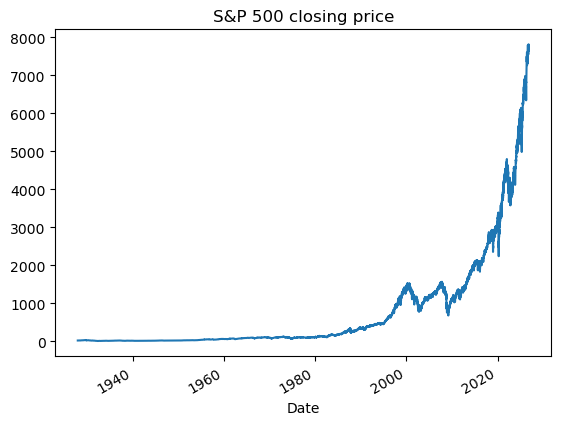

In [2]:
sp500.plot.line(y="Close", use_index=True, title="S&P 500 closing price", legend=False)

The full available history goes back to 1927. The line plot shows the long-run upward trend of the index, along with the sharp drops of major crashes (for example 1929 and 2008).

### Cleaning Up Columns
`Dividends` and `Stock Splits` are dropped: they are almost always zero for an index like the S&P 500 and are not needed for predicting price direction.

In [3]:
del sp500["Dividends"]
del sp500["Stock Splits"]

### Creating the Prediction Target
- `Tomorrow`: the next day's closing price (`Close` shifted back one row), so each day can be compared against the *next* day.
- `Target`: `1` if tomorrow's close is higher than today's close, otherwise `0`. This is what the model learns to predict.

The most recent day has no "tomorrow" yet, so it is dropped. Otherwise it would be wrongly labelled as a down day.

In [4]:
sp500["Tomorrow"] = sp500["Close"].shift(-1)
sp500 = sp500.dropna(subset=["Tomorrow"]).copy()
sp500["Target"] = (sp500["Tomorrow"] > sp500["Close"]).astype(int)

sp500.tail()

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
2026-10-09,7786.359863,7820.569824,7779.339844,7811.540039,4782640000,7807.240234,0
2026-10-12,7813.040039,7821.669922,7796.939941,7807.240234,4148500000,7805.450195,0
2026-10-13,7795.270020,7814.149902,7786.109863,7805.450195,4869340000,7718.939941,0
2026-10-14,7774.180176,7789.149902,7693.310059,7718.939941,5955580000,7744.060059,1
2026-10-15,7687.310059,7754.149902,7669.660156,7744.060059,6055670000,7659.439941,0


### Limiting the Historical Window
Data from 1927 onwards spans very different market regimes (different regulation, trading behaviour and economic structure). Using only data from 1990 gives a more realistic picture of how a model would perform on the market as it behaves today.

In [5]:
sp500 = sp500.loc["1990-01-01":].copy()
sp500.shape

(9265, 7)

## First Model: Quick Sanity Check
Before building a proper validation setup, a single train/test split (holding out only the last 100 trading days) checks that the model can fit and predict at all. This number should **not** be trusted as a performance estimate: it comes from one short, contiguous period, so it depends heavily on which days happen to be held out.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

model = RandomForestClassifier(n_estimators=100, min_samples_split=100, random_state=1)

train = sp500.iloc[:-100]
test = sp500.iloc[-100:]
predictors = ["Close", "Volume", "Open", "High", "Low"]

model.fit(train[predictors], train["Target"])
preds = pd.Series(model.predict(test[predictors]), index=test.index, name="Predictions")

single_split_precision = precision_score(test["Target"], preds)
single_split_base_rate = test["Target"].mean()

print(f"Single-split precision (last 100 days): {single_split_precision:.3f}")
print(f"Share of those 100 days the market closed higher: {single_split_base_rate:.3f}")

Single-split precision (last 100 days): 0.511
Share of those 100 days the market closed higher: 0.470


## Building a Proper Backtesting System
A trustworthy estimate has to mirror how the model would be used in practice: trained only on the past, tested on data it has never seen, and moving forward through time.

- `predict()` fits the model on a training window and returns its predictions next to the true target for a test window.
- `backtest()` runs a **walk-forward validation**. Starting after the first 10 years of data (`start=3650`), it trains on everything up to a point in time, tests on the following year (`step=365`), then moves the window forward one year and repeats. This simulates retraining and forecasting one year at a time instead of testing on a single arbitrary slice.

In [7]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds = pd.Series(preds, index=test.index, name="Predictions")
    return pd.concat([test["Target"], preds], axis=1)


def backtest(data, model, predictors, start=3650, step=365):
    all_predictions = []
    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i + step)].copy()
        all_predictions.append(predict(train, test, predictors, model))
    return pd.concat(all_predictions)


predictions = backtest(sp500, model, predictors)

counts = predictions["Predictions"].value_counts()
precision_base = precision_score(predictions["Target"], predictions["Predictions"])
base_rate_base = predictions["Target"].mean()

print(f"Days predicted down: {counts.get(0, 0):,}  |  Days predicted up: {counts.get(1, 0):,}")
print(f"Walk-forward precision: {precision_base:.3f}")
print(f"Base rate (share of days the market closed higher): {base_rate_base:.3f}")

Days predicted down: 3,560  |  Days predicted up: 2,055
Walk-forward precision: 0.538
Base rate (share of days the market closed higher): 0.545


### How to read this
**Precision** here is the share of the model's "up" calls that were correct. The right yardstick is the **base rate**: the market closes higher on roughly 54-55% of days, so always guessing "up" is already right about that often. A model only adds value if its precision is clearly above the base rate.

With these basic price and volume features, the walk-forward precision comes out slightly *below* the base rate, so the model has no real edge over assuming the market always goes up. That is a common and expected result: raw price history alone is a very weak signal.

## Second Attempt: Adding Rolling-Window Features
To give the model more signal, new features are built over several time horizons (2, 5, 60, 250 and 1000 days):

- `Close_Ratio_N`: today's close divided by its N-day average. Above 1 means the price is above its recent average.
- `Trend_N`: the number of up days over the previous N days. `shift(1)` keeps this strictly in the past, so it never uses information from the day being predicted.

The longest window (1000 days, about 4 years) leaves empty values at the start of the data, so those rows are dropped before training.

In [8]:
horizons = [2, 5, 60, 250, 1000]
new_predictors = []

for horizon in horizons:
    rolling_avg = sp500["Close"].rolling(horizon).mean()

    ratio_column = f"Close_Ratio_{horizon}"
    sp500[ratio_column] = sp500["Close"] / rolling_avg

    trend_column = f"Trend_{horizon}"
    sp500[trend_column] = sp500["Target"].shift(1).rolling(horizon).sum()

    new_predictors += [ratio_column, trend_column]

sp500 = sp500.dropna()
sp500.shape

(8265, 17)

## Re-running the Backtest with the New Features
Two changes from the first model:
- **More trees, more flexible splits:** `n_estimators=200` and `min_samples_split=50`.
- **A confidence threshold:** `predict_proba()` replaces `predict()`, and a day is only called "up" if the model is **at least 60% confident** (instead of the default 50%). This trades recall for precision: the model calls "up" less often, but should be more accurate when it does.

In [9]:
THRESHOLD = 0.6

model = RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1)


def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    probs = model.predict_proba(test[predictors])[:, 1]
    preds = pd.Series((probs >= THRESHOLD).astype(int), index=test.index, name="Predictions")
    return pd.concat([test["Target"], preds], axis=1)


predictions = backtest(sp500, model, new_predictors)

precision_new = precision_score(predictions["Target"], predictions["Predictions"])
base_rate_new = predictions["Target"].mean()
n_up_new = int(predictions["Predictions"].sum())

print(f"Days called up: {n_up_new:,} of {len(predictions):,}")
print(f"Walk-forward precision: {precision_new:.3f}")
print(f"Base rate over this test period: {base_rate_new:.3f}")

Days called up: 716 of 4,615
Walk-forward precision: 0.566
Base rate over this test period: 0.544


The model now calls "up" far less often than before, which is the threshold doing its job. Compare the precision with the base rate printed above: the base rate is recalculated for this test period, since the longer rolling windows shorten the usable history.

## Which Features Actually Mattered?
A Random Forest's `feature_importances_` shows how much each feature contributed to its decisions. Checking this directly avoids assuming which features mattered. For this chart only, a model is fit on the full dataset to read the importances; it is not used for any backtest result.

In [10]:
import plotly.graph_objects as go

final_model = RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1)
final_model.fit(sp500[new_predictors], sp500["Target"])

importances = pd.Series(final_model.feature_importances_, index=new_predictors).sort_values(ascending=False)

fig = go.Figure(go.Bar(
    x=importances.values,
    y=importances.index,
    orientation="h",
    marker_color="#4C72B0",
    hovertemplate="%{y}: %{x:.4f}<extra></extra>"
))
fig.update_layout(
    title=dict(text="Feature Importance - Random Forest", font=dict(size=17)),
    xaxis_title="Importance", yaxis_title="Feature",
    template="plotly_white", yaxis=dict(autorange="reversed"), height=450
)
fig.show()

**Result:** the five `Close_Ratio_*` features (price relative to its recent average) carry the most weight, each around 0.14-0.16 and spread evenly across every time horizon. The `Trend_*` features (how often the market rose recently) matter less, and among them longer horizons count for more: `Trend_1000` is about 0.085, while `Trend_2` is only about 0.014. In other words, the model leans mainly on how far today's price sits from its recent average.

Importance shows what the model *used*, not that those features genuinely predict the market.

## Does the Model Hold Up Across Different Years?
A single overall precision score can hide a lot: a model might do well in calm years and fall apart in turbulent ones. Breaking precision down **by year** shows whether performance is stable or concentrated in a few easy periods.

Red bars mark years where precision was below 0.5 (worse than a coin flip), and the dashed line is the average across years. The final year is only partial, and years where the model made very few "up" calls give noisy scores, so individual bars should be read with care.

In [11]:
yearly_precision = (predictions
                    .groupby(predictions.index.year)[["Target", "Predictions"]]
                    .apply(lambda g: precision_score(g["Target"], g["Predictions"], zero_division=0))
                    .rename("Precision"))

fig = go.Figure(go.Bar(
    x=yearly_precision.index.astype(str),
    y=yearly_precision.values,
    marker_color=["#d62728" if p < 0.5 else "#2ca02c" for p in yearly_precision.values],
    hovertemplate="%{x}: %{y:.3f}<extra></extra>"
))
fig.add_hline(y=yearly_precision.mean(), line_dash="dash", line_color="gray",
              annotation_text=f"Average: {yearly_precision.mean():.3f}")
fig.update_layout(
    title=dict(text="Model Precision by Year (Walk-Forward Backtest)", font=dict(size=17)),
    xaxis_title="Year", yaxis_title="Precision",
    template="plotly_white", showlegend=False
)
fig.show()

**Result:** precision averages about 0.59 across years. The strongest years are 2023 (0.83), 2021 (0.73) and 2014 (0.70). The weakest are 2015 (0.41), 2016 (0.44), 2022 (0.46) and the partial year 2026 (0.44), all below 0.5. Notably, 2008 (0.53) and 2009 (0.67) were not weak years, so the model is not especially fragile in a crash. Its weak years look more like choppy, directionless markets than sharp trending ones.

## Comparing Against Other Models
Random Forest was used throughout, so it is worth checking whether a different model type does meaningfully better on the **same features and the same walk-forward backtest**. This is a fair, like-for-like comparison rather than trusting the first model tried.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier


def predict_thresh(train, test, predictors, model, threshold=THRESHOLD):
    model.fit(train[predictors], train["Target"])
    probs = model.predict_proba(test[predictors])[:, 1]
    preds = pd.Series((probs >= threshold).astype(int), index=test.index, name="Predictions")
    return pd.concat([test["Target"], preds], axis=1)


def backtest_generic(data, model, predictors, start=3650, step=365, threshold=THRESHOLD):
    all_predictions = []
    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i + step)].copy()
        all_predictions.append(predict_thresh(train, test, predictors, model, threshold))
    return pd.concat(all_predictions)


models_to_compare = {
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=1),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}

model_results = []
for name, mdl in models_to_compare.items():
    preds = backtest_generic(sp500, mdl, new_predictors)
    p = precision_score(preds["Target"], preds["Predictions"], zero_division=0)
    model_results.append({"Model": name, "Precision": round(p, 4)})

model_results_df = pd.DataFrame(model_results).sort_values("Precision", ascending=False).reset_index(drop=True)
model_results_df

,Model,Precision
0,Random Forest,0.5656
1,Gradient Boosting,0.5602
2,Logistic Regression,0.5514


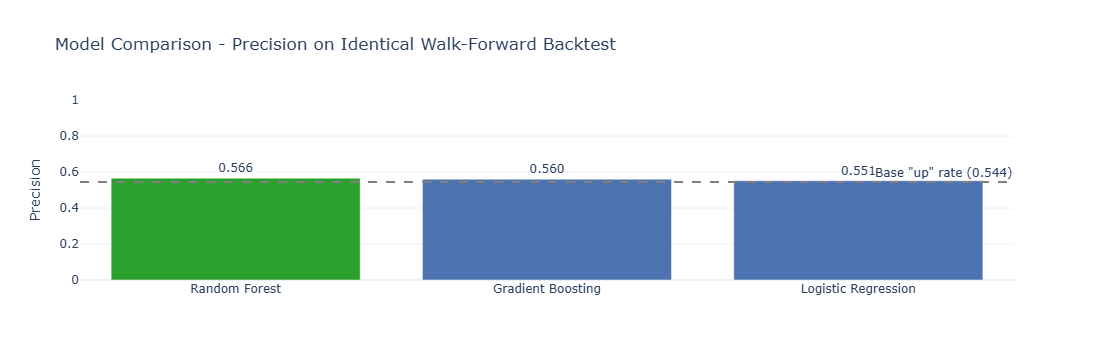

In [13]:
colors = ["#2ca02c" if m == model_results_df.iloc[0]["Model"] else "#4C72B0" for m in model_results_df["Model"]]

fig = go.Figure(go.Bar(
    x=model_results_df["Model"], y=model_results_df["Precision"],
    text=model_results_df["Precision"].apply(lambda v: f"{v:.3f}"),
    textposition="outside", marker_color=colors,
    hovertemplate="%{x}: %{y:.4f}<extra></extra>"
))
fig.add_hline(y=base_rate_new, line_dash="dash", line_color="gray",
              annotation_text=f'Base "up" rate ({base_rate_new:.3f})')
fig.update_layout(
    title=dict(text="Model Comparison - Precision on Identical Walk-Forward Backtest", font=dict(size=17)),
    yaxis_title="Precision", yaxis=dict(range=[0, 1]), template="plotly_white", showlegend=False
)
fig.show()

**Result:** Random Forest scores 0.566, Gradient Boosting 0.560 and Logistic Regression 0.551. All three land within about 1.5 points of each other and only slightly above the base rate (dashed line, 0.544). A simple logistic regression does nearly as well as the tree ensembles, which points to the features, not the algorithm, as the limiting factor: swapping in a fancier model is unlikely to help without genuinely new information.

## Does This Actually Make Money? A Simple Trading Strategy Backtest
Precision alone does not show whether a model is useful for trading. To test that directly, a simple strategy is simulated: **be invested in the S&P 500 only on days the model predicts "up" with high confidence, and hold cash otherwise.** It is compared with plain **buy-and-hold** over the same period.

*This is a simplified simulation. It ignores transaction costs, taxes and slippage, so real-world returns would be lower than shown.*

In [14]:
strategy_df = sp500.loc[predictions.index].copy()
strategy_df["Daily_Return"] = strategy_df["Close"].pct_change().shift(-1)   # next day's return, aligned to today's signal
strategy_df["Signal"] = predictions["Predictions"]

# Earn the next day's return only when the model signals "up"; otherwise sit in cash
strategy_df["Strategy_Return"] = strategy_df["Daily_Return"] * strategy_df["Signal"]

strategy_df["Strategy_Growth"] = (1 + strategy_df["Strategy_Return"].fillna(0)).cumprod()
strategy_df["BuyHold_Growth"] = (1 + strategy_df["Daily_Return"].fillna(0)).cumprod()

fig = go.Figure()
fig.add_trace(go.Scatter(x=strategy_df.index, y=strategy_df["BuyHold_Growth"],
                         mode="lines", name="Buy & Hold", line=dict(color="#4C72B0", width=2)))
fig.add_trace(go.Scatter(x=strategy_df.index, y=strategy_df["Strategy_Growth"],
                         mode="lines", name="Model Strategy", line=dict(color="#d62728", width=2)))
fig.update_layout(
    title=dict(text="Growth of $1: Model Strategy vs. Buy & Hold", font=dict(size=17)),
    xaxis_title="Date", yaxis_title="Growth of $1 (cumulative)",
    template="plotly_white",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)
fig.show()

final_strategy = strategy_df["Strategy_Growth"].iloc[-1]
final_buyhold = strategy_df["BuyHold_Growth"].iloc[-1]
print(f"Final growth of $1 - Model Strategy: {final_strategy:.2f}x   |   Buy & Hold: {final_buyhold:.2f}x")

Final growth of $1 - Model Strategy: 2.33x   |   Buy & Hold: 5.78x


**Result:** the model strategy grew \$1 to about \$2.33, while buy-and-hold grew it to about \$5.78, so the strategy clearly underperforms simply holding the index. The chart shows it did better than buy-and-hold through the 2008-2009 crash and stayed ahead until around 2016, then fell steadily behind during the long bull market that followed.

A model can show a small apparent edge in precision and still lose to buy-and-hold. The strategy only invests when the model is confident, so it sits in cash on most days and gives up much of the market's long-run upward drift. Precision measures how often the "up" calls are right, not how much money the strategy makes. Also, with only 716 "up" calls, the sampling noise on precision is roughly 2 points, so the 2-point edge over the base rate is not clearly distinguishable from chance.

## Where Exactly Is the Model Wrong?
A confusion matrix breaks precision down into the types of correct and incorrect calls, which shows the *kind* of error the model makes most.

- **Bottom-right (true positives):** called "up", and the market rose.
- **Top-right (false positives):** called "up", but the market fell. These are the costly mistakes.
- **Bottom-left (false negatives):** stayed out, but the market rose. This is missed opportunity.

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(predictions["Target"], predictions["Predictions"])
labels = ["Down (0)", "Up (1)"]

fig = go.Figure(data=go.Heatmap(
    z=cm, x=labels, y=labels, colorscale="Blues",
    text=cm, texttemplate="%{text}", textfont=dict(size=16),
    hovertemplate="Actual: %{y}<br>Predicted: %{x}<br>Count: %{z}<extra></extra>"
))
fig.update_layout(
    title=dict(text="Confusion Matrix - Final Model", font=dict(size=17)),
    xaxis_title="Predicted", yaxis_title="Actual",
    template="plotly_white", height=450, width=500
)
fig.show()

**Result:** the model makes 405 true positives and 311 false positives (precision 405 / 716 = 0.566), but 2,106 false negatives. Of the 2,511 days the market actually rose, it caught only about one in six. That is the missed opportunity behind the strategy result above: the model avoids many bad calls, but at the cost of sitting out most of the market's gains.

## Results Summary
The table and figures below are generated by the code, so they always match the outputs above.

In [16]:
summary = pd.DataFrame({
    "Approach": [
        "Single split, last 100 days (basic features)",
        "Walk-forward backtest, basic features",
        f"Walk-forward backtest, rolling features + {THRESHOLD} threshold",
    ],
    "Precision": [single_split_precision, precision_base, precision_new],
    "Base rate (same test period)": [single_split_base_rate, base_rate_base, base_rate_new],
}).round(3)
summary["Edge over base rate"] = (summary["Precision"] - summary["Base rate (same test period)"]).round(3)

display(summary)

print(f"\nGrowth of $1 - Model Strategy: {final_strategy:.2f}x  |  Buy & Hold: {final_buyhold:.2f}x")
print("Model strategy beat buy-and-hold." if final_strategy > final_buyhold
      else "Model strategy did not beat buy-and-hold.")

,Approach,Precision,Base rate (same test period),Edge over base rate
0,"Single split, last 100 days (basic features)",0.511,0.470,0.041
1,"Walk-forward backtest, basic features",0.538,0.545,-0.007
2,"Walk-forward backtest, rolling features + 0.6 ...",0.566,0.544,0.022



Growth of $1 - Model Strategy: 2.33x  |  Buy & Hold: 5.78x
Model strategy did not beat buy-and-hold.


## Conclusion & Key Takeaways

- **How you evaluate matters more than which model you use.** A single 100-day split is a noisy estimate. During development, this notebook's single-split precision swung between about 0.45 and 0.89 just from the data refreshing by a few days, which is exactly why the walk-forward backtest is the number to trust.
- **Always compare against the base rate.** The market closes higher on roughly 54-55% of days. The basic-feature model scored slightly below that (0.538 vs 0.545), and the final model sat only about 2 points above it (0.566 vs 0.544), within the range of chance for 716 calls.
- **Precision is not profit.** The final model's strategy turned \$1 into about \$2.33, against \$5.78 for buy-and-hold. A confident-only strategy sits out most of the market, so a modest precision edge does not beat simply holding the index.
- **The information is the limit.** Price and volume history alone is a weak predictor of next-day direction: three very different models land within about 1.5 points of each other.

**Limitations and next steps:** the strategy ignores transaction costs and taxes; the features use only price and volume; and precision is only one metric. Natural extensions are adding volatility or macroeconomic features, predicting returns instead of direction, tuning the confidence threshold, and including trading costs in the simulation.